<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/JS06-ANN/tugas_ann.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install annoy

!pip install faiss-cpu
#!pip install faiss-gpu

!pip install hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520037 sha256=46ac48c60c370d96e63b05d644e2ad6272eb6d1631588606dec5fe29dfdfa842
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 37.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679799 sha256=1d4c9ac181147abca8124ea58debc332ca89ab7349dcc79494177995aa819be4
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib


In [5]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")


Exact NN done in 3.834 s
Annoy done in 2.762 s
HNSW done in 6.863 s
FAISS IVF done in 0.329 s

=== Ringkasan Waktu (detik) ===
Exact NN : 3.834
Annoy    : 2.762
HNSW     : 6.863
FAISS    : 0.329


Hasil dari Pydroid 3

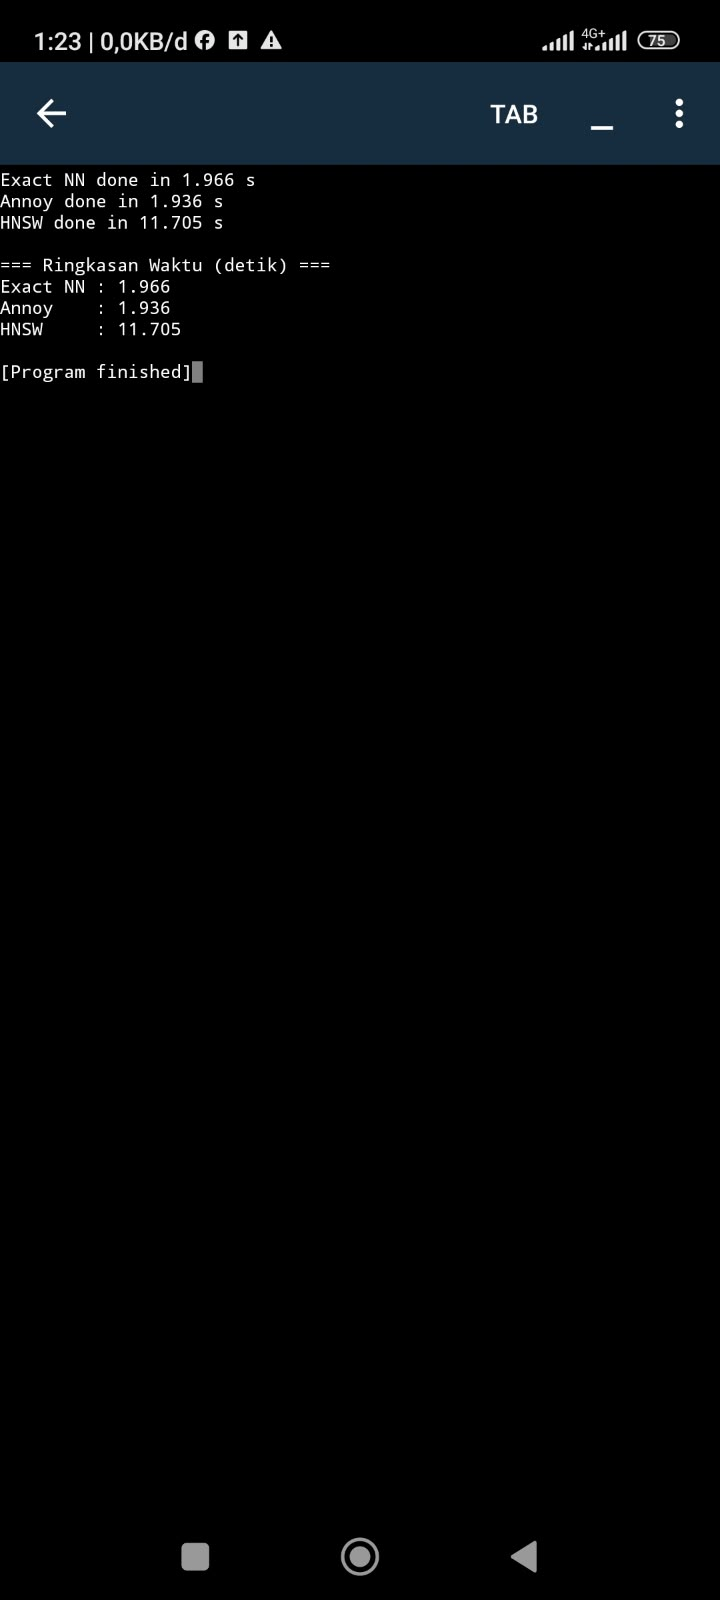

Berikut adalah draf jawaban lengkap yang sudah diperbarui dengan memasukkan spesifikasi perangkat **Xiaomi Redmi Note 11** Anda:

---

### **1. Hasil Eksekusi Kode**

* **Google Colab (Lingkungan Cloud x86_64):**
* **Exact NN:** 3.834 detik


* **Annoy:** 2.762 detik


* **HNSW:** 6.863 detik


* **FAISS IVF:** 0.329 detik




* **Pydroid 3 (Smartphone Android / ARM64):**
* **Exact NN:** 1.966 detik


* **Annoy:** 1.936 detik


* **HNSW:** 11.705 detik


* **FAISS IVF:** **N/A (Tidak dapat dijalankan / diinstal)**




---

### **2. Spesifikasi Perangkat yang Digunakan**

* **Google Colab:** Google Compute Engine Instance (Python 3, RAM 12.67 GB, Intel Xeon / x86_64 Architecture).


* **Smartphone (Pydroid 3):**
* **Model Smartphone:** Xiaomi Redmi Note 11
* **Prosesor (SoC):** Qualcomm Snapdragon 680 (8-core, up to 2.4 GHz)
* **Arsitektur:** ARM64 (AArch64 / ARMv8)
* **Sistem Operasi:** Android (MIUI / HyperOS)



---

### **3. Analisis Hasil dan Penjelasan Kendala FAISS**

**A. Analisis Performa Algoritma**

1. **FAISS IVF (Paling Unggul di Cloud):** Pada Google Colab, FAISS IVF menjadi yang tercepat (0.329 detik) karena memanfaatkan teknik *Inverted File Index* yang teroptimasi khusus untuk instruksi SIMD/AVX pada prosesor server x86.


2. **Annoy:** Memberikan performa eksekusi yang konsisten cepat di kedua platform (2.762 s di Colab vs 1.936 s di Pydroid 3) karena menggunakan struktur *random projection trees* berbasis C++ yang efisien.


3. **Exact NN (Brute-Force):** Membandingkan jarak secara langsung ($O(N^2)$). Meskipun menjamin 100% presisi, waktu eksekusinya relatif lambat untuk dataset yang lebih besar.
4. **HNSW:** Memiliki waktu *overhead* pembuatan graf bernavigasi bertingkat yang tinggi pada dataset ini (6.863 s di Colab dan 11.705 s di Pydroid 3). Namun, HNSW sangat unggul dalam skenario pencarian *real-time* berskala besar.



**B. Alasan FAISS Tidak Dapat Dijalankan di Pydroid 3**

* **Kompatibilitas Arsitektur Hardware:** Paket `faiss-cpu` di PyPI hanya menyediakan *pre-compiled binary wheel* untuk arsitektur server/PC (**x86_64**). Sementara itu, Xiaomi Redmi Note 11 menggunakan chipset Qualcomm Snapdragon 680 yang berbasis arsitektur **ARM64 (AArch64)**.
* **Ketergantungan Low-Level C++:** FAISS memerlukan pustaka aljabar linier level rendah (seperti OpenBLAS/LAPACK) yang tidak tersedia secara otomatis pada lingkungan kompilasi lokal Pydroid 3 di Android.
* **Solusi/Alternatif:** Untuk pengujian di Android (Pydroid 3), pengujian difokuskan pada pustaka **Annoy** dan **HNSWLIB** karena keduanya mendukung kompilasi C++ lokal secara otomatis saat diinstal via `pip`.